# 04 Model 1: logistic regression on hand-crafted features

Model 1 trained on the **74 hand-crafted features** of `03_features.ipynb`
(20 name features + 54 TLD features), written as the four steps of a model:

1. **Define a predictor**: P(class | x) = softmax(x W + b)
2. **Define a loss**: weighted cross-entropy + L2 penalty
3. **Optimize the loss**: find W and b with L-BFGS
4. **Test the model**: macro-F1, DGA precision/recall, ROC-AUC and recall per family

The code lives in Python files, loaded here:

| File | What it holds |
|---|---|
| `src/data/dataset.py` | `load_splits()`: the team's fixed split + sample weights |
| `src/features/build.py` | `build_features()`: all 74 features, cached on disk |
| `src/models/logreg.py` | `LogReg`: predictor (step 1), loss (step 2), optimizer (step 3) |
| `src/models/evaluate.py` | metrics (step 4), shared with `02_baseline.ipynb` |

Each model is trained in the two setups of the project, **binary** (DGA / legit) and
**family-first** (legit or one of 103 families, collapsed with P(DGA) = 1 − P(legit)),
with and without the TLD features, and with the sample weights.

## Settings

`SAMPLE` trains on a random subset of the training set, the same 100k rows as
`02_baseline.ipynb` (same seed), so the results can be compared with the TF-IDF baseline.
Set it to `None` for the full 1.6M training rows (a few minutes per family-first fit).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

SAMPLE = 100_000   # None = full training set
SEED = 0           # same as 02_baseline.ipynb
EVAL_SET = "val"   # "test" only for the final results

## Data and features

`load_splits()` reads the team's fixed train / validation / test split and adds the
sample weights to train. `build_features()` computes the 74 features of
`03_features.ipynb` (n-gram and Markov counts learned on the full training set, out-of-fold).
The first run takes 10–20 minutes and saves the result in `data/processed/features/`;
later runs load it in seconds.

In [2]:
import numpy as np
import pandas as pd

from src.data.dataset import load_splits
from src.features.build import build_features

train_full, val, test = load_splits()
feats = build_features(train_full, val, test)
name_cols, tld_cols = feats["name_cols"], feats["tld_cols"]

# Training rows: the same 100k sample as 02_baseline.ipynb (or all rows)
train = train_full.sample(n=SAMPLE, random_state=SEED) if SAMPLE else train_full
X_train_all = feats["train"].loc[train.index]
evaluate = test if EVAL_SET == "test" else val
X_eval_all = feats["test"] if EVAL_SET == "test" else feats["val"]
y_eval = (evaluate["label"] == "dga").astype(int).to_numpy()

print(f"train: {len(train):,} rows (of {len(train_full):,}), {EVAL_SET}: {len(evaluate):,} rows")
print(f"features: {len(name_cols)} name + {len(tld_cols)} TLD = {X_train_all.shape[1]}")

train: 100,000 rows (of 1,599,468), val: 199,933 rows
features: 20 name + 54 TLD = 74


## Step 1: Define a predictor

For one domain with feature vector **x** (74 numbers, standardized to mean 0 and std 1
on the training set), the model gives every class a score and turns the scores into
probabilities:

- score of class k: z_k = x · w_k + b_k
- P(class k | x) = exp(z_k) / Σ_j exp(z_j)  (softmax)

**Binary:** 2 classes (DGA, legit); this is ordinary logistic regression.
**Family-first:** 104 classes (legit + 103 families); P(DGA) = 1 − P(legit).

The four runs below differ only in the target (label or family) and the input columns
(with or without the 54 TLD columns).

In [3]:
# The four runs: setup x TLD
runs = {
    (setup, tld): {
        "target": train["label"] if setup == "binary" else train["family"],
        "cols": name_cols + tld_cols if tld == "yes" else name_cols,
    }
    for setup in ["binary", "family"] for tld in ["yes", "no"]
}
for (setup, tld), r in runs.items():
    print(f"{setup:6s} | TLD {tld:3s} | {len(r['cols']):2d} features | "
          f"{r['target'].nunique():3d} classes")

binary | TLD yes | 74 features |   2 classes
binary | TLD no  | 20 features |   2 classes
family | TLD yes | 74 features | 104 classes
family | TLD no  | 20 features | 104 classes


## Step 2: Define a loss

The loss measures how wrong the predicted probabilities are on the training set:

loss = Σ_i w_i · (−log P(true class of i | x_i)) / Σ_i w_i  +  λ/2 · ‖W‖²

- **Cross-entropy** (−log P): small when the model gives the true class a high
  probability, large when it gives it a low one.
- **Sample weights** w_i (from `load_splits()`): legit and DGA count half each, and
  small DGA families count more.
- **L2 penalty** (λ = 1e-4): keeps the weights small, against overfitting.

At the start (all weights 0) every class gets the same probability, so the loss is
log(number of classes): log 2 ≈ 0.69 for binary, log 104 ≈ 4.64 for family-first.
The code is `LogReg._loss_and_grad` in `src/models/logreg.py`; it also returns the
gradient, which the optimizer needs.

## Step 3: Optimize the loss

`LogReg.fit` starts from W = 0, b = 0 and lets L-BFGS (a gradient-based optimizer from
scipy) lower the loss step by step until it stops improving. The table shows, for each
run, whether it converged, the number of iterations, the final loss and the time; the
plot shows the loss going down.

binary | TLD yes | converged True |  64 iterations | loss 0.2056 | 3 s
binary | TLD no  | converged True |  64 iterations | loss 0.2635 | 2 s
family | TLD yes | converged True | 385 iterations | loss 0.7304 | 180 s
family | TLD no  | converged True | 456 iterations | loss 1.3219 | 258 s


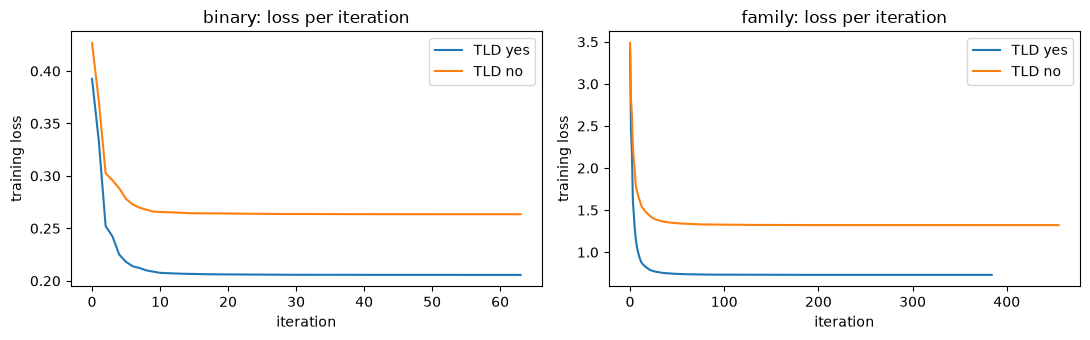

In [4]:
import time
import matplotlib.pyplot as plt

from src.models.logreg import LogReg

models = {}
for (setup, tld), r in runs.items():
    model = LogReg(l2=1e-4).fit(X_train_all[r["cols"]], r["target"],
                                sample_weight=train["weight"])
    models[setup, tld] = model
    print(f"{setup:6s} | TLD {tld:3s} | converged {model.converged_} | "
          f"{model.n_iter_:3d} iterations | loss {model.final_loss_:.4f} | "
          f"{model.fit_seconds_:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, setup in zip(axes, ["binary", "family"]):
    for tld in ["yes", "no"]:
        ax.plot(models[setup, tld].loss_history_, label=f"TLD {tld}")
    ax.set_title(f"{setup}: loss per iteration")
    ax.set_xlabel("iteration")
    ax.set_ylabel("training loss")
    ax.legend()
plt.tight_layout()
plt.show()

## Step 4: Test the model

Each model predicts P(DGA) for every validation domain (family-first: 1 − P(legit)).
A domain is called DGA when P(DGA) ≥ 0.5. Metrics on the DGA / legit decision, with
the functions of `src/models/evaluate.py` (the same as in `02_baseline.ipynb`).
The last column repeats the macro-F1 of the TF-IDF baseline (`02_baseline.ipynb`,
same 100k training rows, with weights) for comparison.

In [5]:
from src.models.evaluate import binary_metrics, p_dga_from_proba

# Macro-F1 of the TF-IDF baseline (02_baseline.ipynb, 100k rows, with weights)
TFIDF_F1 = {("binary", "yes"): 0.9344, ("binary", "no"): 0.9135,
            ("family", "yes"): 0.9429, ("family", "no"): 0.9198}

p_dga, results = {}, {}
for (setup, tld), model in models.items():
    proba = model.predict_proba(X_eval_all[runs[setup, tld]["cols"]])
    p_dga[setup, tld] = p_dga_from_proba(proba, model.classes_)
    results[setup, tld] = {**binary_metrics(y_eval, p_dga[setup, tld]),
                           "tfidf_macro_f1": TFIDF_F1[setup, tld]}

table = pd.DataFrame(results).T.round(4)
table.index.names = ["setup", "TLD"]
table

macro_f1  dga_precision  dga_recall  roc_auc  tfidf_macro_f1
setup  TLD                                                              
binary yes    0.9210         0.9331      0.9070   0.9750          0.9344
       no     0.9089         0.9236      0.8917   0.9588          0.9135
family yes    0.9397         0.9454      0.9332   0.9858          0.9429
       no     0.9149         0.9329      0.8942   0.9640          0.9198

### Family-first vs binary

The project's question: does training on the families first help the DGA / legit
decision? Positive gain = family-first is better. (The 5-seed comparison with standard
deviations comes later; this is one run.)

In [6]:
f1 = table["macro_f1"].unstack("setup")
f1["gain family-first"] = f1["family"] - f1["binary"]
f1

setup,binary,family,gain family-first
TLD,,,
no,0.9089,0.9149,0.0060
yes,0.9210,0.9397,0.0187


### Which DGA families are missed?

Recall per DGA family (share of its domains called DGA), family-first vs binary, with
TLD. The 10 families with the lowest recall in the family-first setup.

In [7]:
from src.models.evaluate import recall_per_family

recall = pd.DataFrame({
    setup: recall_per_family(evaluate["family"], y_eval,
                             (p_dga[setup, "yes"] >= 0.5).astype(int))
    for setup in ["binary", "family"]})
recall.sort_values("family").head(10).round(3)

,binary,family
matsnu,0.035,0.071
nymaim2,0.066,0.102
nivdort,0.130,0.349
bigviktor,0.248,0.366
bigviktor_subdomain,0.475,0.475
qsnatch,0.370,0.602
darkshell,0.967,0.611
vawtrak,0.615,0.648
virut,0.498,0.663
gozi,0.618,0.684


**Model 1 result** (validation macro-F1, 100k rows, one run)

| Setup | TLD | Hand-crafted (74) | TF-IDF (31k) |
|---|---|---|---|
| binary | yes | 0.921 | 0.934 |
| binary | no | 0.909 | 0.914 |
| family-first | yes | **0.940** | 0.943 |
| family-first | no | 0.915 | 0.920 |

- Family-first beats binary; the gain is twice the TF-IDF baseline's (+0.019 vs +0.009).
- Family-first helps hard families (nivdort, qsnatch, virut) but hurts darkshell.
- Dictionary DGAs (matsnu, nymaim2) are still almost never caught.
- Next: 5 seeds and the full training set.

## Repeat over 5 seeds

The results above come from one random sample of 100k training rows. Here the four
setups are trained again on 5 different samples (seeds 0–4), in parallel
(`run_seeds` in `src/models/experiment.py`), to see how much the results vary.
Seed 0 is the same sample as above.

In [8]:
from src.models.experiment import run_seeds, summarize

seed_results = run_seeds(feats, train_full, evaluate, X_eval_all,
                         seeds=range(5), sample=SAMPLE)
seed_results[["macro_f1", "dga_precision", "dga_recall", "roc_auc", "fit_s"]].astype(float).round(4)

macro_f1  dga_precision  dga_recall  roc_auc  fit_s
seed setup  TLD                                                     
0    binary no     0.9089         0.9236      0.8917   0.9588    9.0
            yes    0.9210         0.9331      0.9070   0.9750   14.0
     family no     0.9149         0.9329      0.8942   0.9640  867.0
            yes    0.9396         0.9454      0.9332   0.9858  814.0
1    binary no     0.9087         0.9216      0.8934   0.9588    6.0
            yes    0.9212         0.9319      0.9088   0.9749   16.0
     family no     0.9144         0.9295      0.8969   0.9639  920.0
            yes    0.9393         0.9436      0.9345   0.9857  707.0
2    binary no     0.9090         0.9237      0.8918   0.9588    6.0
            yes    0.9211         0.9330      0.9075   0.9752   13.0
     family no     0.9154         0.9333      0.8948   0.9639  921.0
            yes    0.9395         0.9456      0.9327   0.9858  883.0
3    binary no     0.9089         0.9222      0.8931   0.9588   10.0
            yes    0.9211         0.9327      0.9077   0.9750   16.0
     family no     0.9149         0.9310      0.8963   0.9640  940.0
            yes    0.9397         0.9459      0.9327   0.9858  842.0
4    binary no     0.9085         0.9217      0.8928   0.9588    8.0
            yes    0.9207         0.9322      0.9074   0.9750   15.0
     family no     0.9146         0.9315      0.8950   0.9638  376.0
            yes    0.9395         0.9442      0.9343   0.9857  427.0

### Mean ± standard deviation, and the family-first gain

Macro-F1 averaged over the 5 seeds. The gain is family-first minus binary, computed seed
by seed (same sample), then averaged. Following the proposal, family-first counts as
better if the mean gain is larger than its standard deviation.

In [9]:
summary, gains = summarize(seed_results)
print(summary.round(4), "\n")
print(gains.round(4))

              mean     std
setup  TLD                
binary no   0.9088  0.0002
       yes  0.9210  0.0002
family no   0.9148  0.0004
       yes  0.9395  0.0001 

    mean_gain  std_gain family_first_better
TLD                                        
yes  0.018518  0.000264                True
no   0.006054  0.000239                True
